# 1. Load Libarires, Seed and Device (Google Colab)

In [1]:
###############################################################
# Importing necessary libraries
###############################################################
import os
from tqdm import tqdm
import numpy as np
import matplotlib.pyplot as plt
import kagglehub
import random
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.utils.data import TensorDataset, DataLoader
from torchvision import datasets, transforms
from torchvision.utils import save_image

# Setting a seed for reproducibility
random.seed(99)
np.random.seed(99)
torch.manual_seed(99)

# If running in Google Colab, uncomment below to mount your drive:
# from google.colab import drive
# drive.mount('/content/drive', force_remount=True)

# Set device (use GPU if available, otherwise CPU)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Using device: {device}")

Using device: cuda


# 2. Load Dataset, Inspect and Pre-Process images


In [2]:
###############################################################
# Getting the data
###############################################################

# Download the dataset from Kaggle
path = kagglehub.dataset_download("gpiosenka/butterfly-images40-species")

# This dataset contains: 12594 train, 500 test, 500 validation images 224 X 224 X 3 jpg format

# Inspect the raw data
train_raw = datasets.ImageFolder(root=os.path.join(path, "train"))
valid_raw = datasets.ImageFolder(root=os.path.join(path, "valid"))
test_raw = datasets.ImageFolder(root=os.path.join(path, "test"))

print(f"Number of training samples: {len(train_raw)}, Number of valid samples: {len(valid_raw)}, Number of test samples: {len(test_raw)}")
print(f"Number of species (classes): {len(train_raw.classes)}")

# Inspect one image (just to check)
img, label = train_raw[99]
print(f"Check one image: Type: {type(img)}, size (width, height): {img.size}, mode: {img.mode}, species: {train_raw.classes[label]}")



Using Colab cache for faster access to the 'butterfly-images40-species' dataset.
Number of training samples: 12594, Number of valid samples: 500, Number of test samples: 500
Number of species (classes): 100
Check one image: Type: <class 'PIL.Image.Image'>, size (width, height): (224, 224), mode: RGB, species: ADONIS


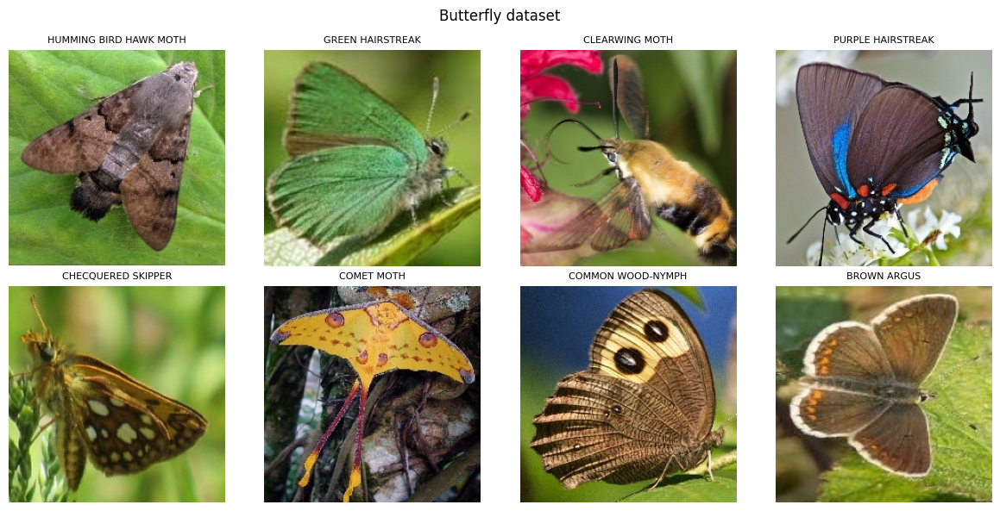

In [3]:
###############################################################
# Exploring the data
###############################################################

# Printing 8 random images from the training set (in their original resolution)
random_indices = random.sample(range(len(train_raw)), 8)
fig, axes = plt.subplots(2, 4, figsize=(12, 6))

for ax, i in zip(axes.flat, random_indices):
    img, label = train_raw[i]
    ax.imshow(img)
    ax.set_title(train_raw.classes[label], fontsize=8)
    ax.axis('off')

plt.suptitle("Butterfly dataset")
plt.tight_layout()
plt.show()

In [4]:
###############################################################
# Resize, normalize to [-1, 1], and DataLoader
###############################################################

# Resize the images to 64x64, convert them to PyTorch tensors and scale them to [-1, 1]
transform = transforms.Compose([
    transforms.Resize((64, 64)), #resize from 224x224 to 64x64
    transforms.ToTensor(), #convert them to tensors
    transforms.Normalize(mean=(0.5, 0.5, 0.5), std=(0.5, 0.5, 0.5)),  #normalise from [0, 1] to [-1, 1] (to match tanh)
])


# GAN only needs train set (doesn't use validation and test set)
train = datasets.ImageFolder(root=os.path.join(path, "train"), transform=transform)

# Set up the dataloader for training
batch_size = 64  #same as notebook for GAN

train_loader = DataLoader(train, batch_size=batch_size,
                          shuffle=True, #reorder
                          drop_last=True, #drop the last incomplete batch (same as notebook)
                          pin_memory=True) #transfer batches from CPU to GPU (faster)

print("Dataset loaded successfully.")

Dataset loaded successfully.


# 3. Adapt the notebook's GAN architecture

- Copy the notebook’s architecture as it is (the baseline), and understand every layer.
- Check with code that the shapes fit our data.
- Train it
- If the butterflies come out poor or training is unstable, come back to the architecture and add improvements. (These changes represent the “experiment with architecture changes” material for the report)

In [14]:
###############################################################
# Settings for all training versions
###############################################################
latent_dim = 256 # size of the latent vector z
num_filters = 128 # number of convolutional filters for each layer
n_epochs = 25 # number of epochs (same as the CAE and VAE)

SAVE_DIR = "results_gan" # results folder for all GAN figures
os.makedirs(SAVE_DIR, exist_ok=True)

In [15]:
###############################################################
# Plotting function (from notebook)
###############################################################
def grid_plot(images, epoch='', name='', n=3, save=False, scale=False, filename='generated_plot.png'):
    if isinstance(images, torch.Tensor):
        images = images.detach().cpu().numpy()

    # Transpose back from (N, C, H, W) to (N, H, W, C) for matplotlib
    if images.ndim == 4 and images.shape[1] in [1, 3]:
        images = np.transpose(images, (0, 2, 3, 1))

    if scale:
        # Rescale from [-1, 1] to [0, 1] for plotting
        images = (images + 1.0) / 2.0
    images = np.clip(images, 0.0, 1.0)

    fig, axes = plt.subplots(n, n, figsize=(6, 6))
    for index, ax in enumerate(axes.flat):
        if index < len(images):
            ax.imshow(images[index])
        ax.axis('off')
    fig.suptitle(f"{name} {epoch}", fontsize=14)
    plt.tight_layout()
    if save:
        plt.savefig(os.path.join(SAVE_DIR, filename), dpi=300)   # save in SAVE_DIR with the given file name
    plt.show()

In [32]:
###############################################################
# Training Function for GANs (slightly different from the notebook)
###############################################################

def train_gan(generator, discriminator, train_loader, latent_dim, n_epochs=20, lr=0.0002, beta_1=0.5, plot_every=5, # plot every 5 epochs
              version='v1'): #save which architecture version we are using

    # Optimizers: two different optimizers, one for each network
    optimizer_d = optim.Adam(discriminator.parameters(), lr=lr, betas=(beta_1, 0.999))
    optimizer_g = optim.Adam(generator.parameters(), lr=lr, betas=(beta_1, 0.999))

    # Loss function: Binary Cross-Entropy
    criterion = nn.BCELoss()

    # Save the averages of each epoch (to be able to plot them)
    d_loss_history = []
    g_loss_history = []
    d_real_history = []
    d_fake_history = []

    # Use the same 9 latent vectors every epoch (better comparison)
    rng = torch.Generator().manual_seed(0) # seed for reproducibility: use the same set of 9 latent vectors (for all training versions)
    fixed_noise = torch.randn(9, latent_dim, generator=rng).to(device)

    for epoch in range(n_epochs):
        total_d_loss, total_g_loss, prob_d_real, prob_d_fake = 0.0, 0.0, 0.0, 0.0

        for real_images, _ in tqdm(train_loader, desc=f"Epoch {epoch+1}/{n_epochs}"):   # in real_images, labels are ignored
            current_batch_size = real_images.size(0)
            real_images = real_images.to(device)

            # Initialise the labels
            real_labels = torch.ones(current_batch_size, 1, device=device)    # prediction = 1 (real data)
            fake_labels = torch.zeros(current_batch_size, 1, device=device)   # prediction = 0 (fake data)

            # ---------------------
            #  Train Discriminator
            # ---------------------
            optimizer_d.zero_grad()

            # Loss on real images
            outputs_real = discriminator(real_images)
            d_loss_real = criterion(outputs_real, real_labels)

            # Loss on fake images
            z = torch.randn(current_batch_size, latent_dim, device=device)
            fake_images = generator(z)
            outputs_fake = discriminator(fake_images.detach())
            d_loss_fake = criterion(outputs_fake, fake_labels)

            # Total loss
            d_loss = d_loss_real + d_loss_fake
            d_loss.backward()
            optimizer_d.step()

            # -----------------
            #  Train Generator
            # -----------------
            optimizer_g.zero_grad()
            outputs = discriminator(fake_images)
            g_loss = criterion(outputs, real_labels)   # Generator wants the discriminator to output 1 (real)
            g_loss.backward()
            optimizer_g.step()

            # -----------------
            #  Summary measures of the training
            # -----------------

            # Add up the values of this batch (runs at every batch)
            total_d_loss += d_loss.item() # discriminator loss
            total_g_loss += g_loss.item() # generator loss
            prob_d_real += outputs_real.mean().item() # average probability that the real images are real according to the discriminator
            prob_d_fake += outputs_fake.mean().item() # average probability that the fake images are real according to the discriminator

        # Average over the batches of this epoch and store it (runs once per epoch)
        n_batches = len(train_loader)
        d_loss_history.append(total_d_loss / n_batches)
        g_loss_history.append(total_g_loss / n_batches)
        d_real_history.append(prob_d_real / n_batches)
        d_fake_history.append(prob_d_fake / n_batches)
        print(f"Epoch {epoch+1}/{n_epochs} - D Loss: {d_loss_history[-1]:.4f} - G Loss: {g_loss_history[-1]:.4f} - "
              f"D(x): {d_real_history[-1]:.3f} - D(G(z)): {d_fake_history[-1]:.3f}")

        # Generate and visualize (plot after the first epoch and every plot_every epochs)
        if epoch == 0 or (epoch + 1) % plot_every == 0:
            generator.eval()
            with torch.no_grad():
                generated_images = generator(fixed_noise)   # NB. use the same 9 latent vectors every time
                grid_plot(generated_images, epoch+1, name=f'Generated images ({version}), epoch', n=3, scale=True,
                          save=True, filename=f"gan_{version}_e{epoch+1:03d}.png")   #saved with version + epoch
            generator.train()

    return d_loss_history, g_loss_history, d_real_history, d_fake_history

In [18]:
###############################################################
# Plot the Training Loss over the epochs
###############################################################
def plot_training_history(d_loss_history, g_loss_history, d_real_history, d_fake_history, version='v1'):
    epochs_range = range(1, len(d_loss_history) + 1)

    # Plot of the losses over the epochs
    plt.figure(figsize=(8,5))
    plt.plot(epochs_range, d_loss_history, marker='o', label='Discriminator loss')
    plt.plot(epochs_range, g_loss_history, marker='o', label='Generator loss')
    plt.xlabel("Epoch")
    plt.ylabel("BCE Loss")
    plt.title(f"GAN Training Loss ({version})")
    plt.legend()
    plt.grid(True)
    plt.tight_layout()
    plt.savefig(os.path.join(SAVE_DIR, f"gan_{version}_training_loss.png"), dpi=300)
    plt.show()

    # Plot of the discriminator's average output over the epochs
    plt.figure(figsize=(8,5))
    plt.plot(epochs_range, d_real_history, marker='o', label='D(x): real images')
    plt.plot(epochs_range, d_fake_history, marker='o', label='D(G(z)): generated images')
    plt.axhline(0.5, linestyle='--', color='grey', label='Equilibrium (0.5)')
    plt.xlabel("Epoch")
    plt.ylabel("Mean discriminator output")
    plt.title(f"GAN Discriminator Outputs ({version})")
    plt.ylim(0, 1)
    plt.legend()
    plt.grid(True)
    plt.tight_layout()
    plt.savefig(os.path.join(SAVE_DIR, f"gan_{version}_discriminator_outputs.png"), dpi=300)
    plt.show()

## Training Version 1

In [5]:
###############################################################
# Build Decoder (from notebook)
###############################################################

class ConvDecoder(nn.Module):
    """
    Build a deconvolutional network for decoding/upscaling latent vectors in PyTorch
    """
    def __init__(self, latent_dim=512, out_channels=3, filters=128, n_upsampling_layers=4, activation_out='sigmoid'):
        super().__init__()
        self.filters = filters
        self.fc = nn.Linear(latent_dim, filters * 4 * 4) #Fully connected layer
        layers = []
        for _ in range(n_upsampling_layers): #Up-sampling layers
            layers.append(nn.ConvTranspose2d(filters, filters, kernel_size=3, stride=2, padding=1, output_padding=1))
            layers.append(nn.ReLU(inplace=True))
        self.deconv_net = nn.Sequential(*layers)
        self.conv_out = nn.Conv2d(filters, out_channels, kernel_size=3, stride=1, padding=1) #128 channels down to 3 colour channels
        self.activation_out = activation_out

    def forward(self, z):
        h = F.relu(self.fc(z))
        h = h.view(-1, self.filters, 4, 4) #Reshape the 2048 numbers into a tiny image of 128 channels and 4×4 pixels.
        h = self.deconv_net(h)
        out = self.conv_out(h)
        if self.activation_out == 'sigmoid':
            return torch.sigmoid(out)
        elif self.activation_out == 'tanh':
            return torch.tanh(out)
        return out

In [6]:
###############################################################
# GAN Discriminator (from notebook)
###############################################################
class Discriminator(nn.Module):
    """
    Discriminator CNN in PyTorch for 64x64 RGB images
    """
    def __init__(self, in_channels=3, filters=128):
        super().__init__()
        self.net = nn.Sequential(
            nn.Conv2d(in_channels, filters, kernel_size=3, stride=2, padding=1),
            nn.LeakyReLU(0.2, inplace=True),
            nn.Conv2d(filters, filters, kernel_size=3, stride=2, padding=1),
            nn.LeakyReLU(0.2, inplace=True),
            nn.Conv2d(filters, filters, kernel_size=3, stride=2, padding=1),
            nn.LeakyReLU(0.2, inplace=True),
            nn.Conv2d(filters, filters, kernel_size=3, stride=2, padding=1),
            nn.LeakyReLU(0.2, inplace=True),
            nn.Flatten(),
            nn.Linear(filters * 4 * 4, 1),
            nn.Sigmoid()
        )

    def forward(self, x):
        return self.net(x)

###############################################################
# GAN Generator (from notebook)
###############################################################
class Generator(nn.Module):
    """
    Generator deconvolutional network with Tanh output activation in [-1, 1]
    """
    def __init__(self, latent_dim=256, out_channels=3, filters=128):
        super().__init__()
        self.decoder = ConvDecoder(latent_dim=latent_dim, out_channels=out_channels, filters=filters, activation_out='tanh')

    def forward(self, z):
        return self.decoder(z)

Epoch 1/25: 100%|██████████| 196/196 [02:04<00:00,  1.57it/s]


Epoch 1/25 - D Loss: 0.6623 - G Loss: 2.6296 - D(x): 0.836 - D(G(z)): 0.197


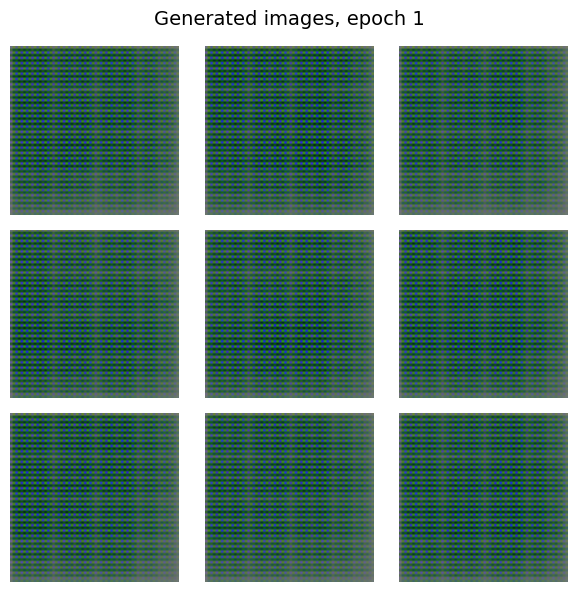

Epoch 2/25: 100%|██████████| 196/196 [00:41<00:00,  4.70it/s]


Epoch 2/25 - D Loss: 0.7798 - G Loss: 2.1488 - D(x): 0.827 - D(G(z)): 0.188


Epoch 3/25: 100%|██████████| 196/196 [00:39<00:00,  4.94it/s]


Epoch 3/25 - D Loss: 0.7910 - G Loss: 2.7432 - D(x): 0.844 - D(G(z)): 0.171


Epoch 4/25: 100%|██████████| 196/196 [00:39<00:00,  4.90it/s]


Epoch 4/25 - D Loss: 0.6531 - G Loss: 2.9860 - D(x): 0.825 - D(G(z)): 0.161


Epoch 5/25: 100%|██████████| 196/196 [00:39<00:00,  4.91it/s]


Epoch 5/25 - D Loss: 0.7349 - G Loss: 2.3067 - D(x): 0.786 - D(G(z)): 0.222


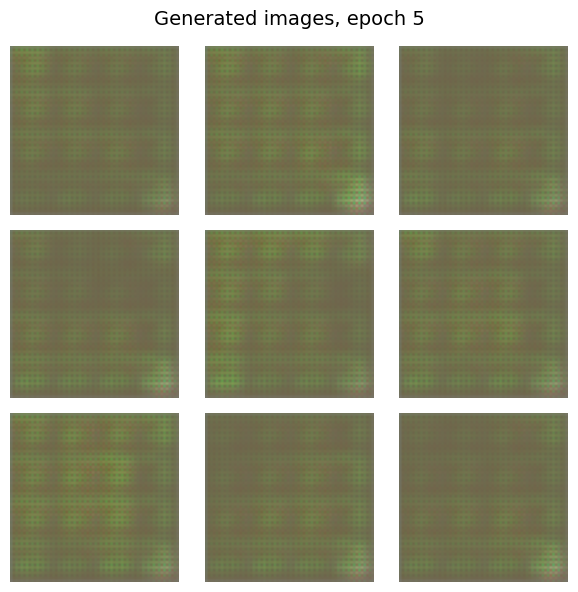

Epoch 6/25: 100%|██████████| 196/196 [00:44<00:00,  4.45it/s]


Epoch 6/25 - D Loss: 0.7895 - G Loss: 2.1268 - D(x): 0.766 - D(G(z)): 0.244


Epoch 7/25: 100%|██████████| 196/196 [00:41<00:00,  4.78it/s]


Epoch 7/25 - D Loss: 0.9488 - G Loss: 1.8175 - D(x): 0.701 - D(G(z)): 0.302


Epoch 8/25: 100%|██████████| 196/196 [00:40<00:00,  4.81it/s]


Epoch 8/25 - D Loss: 1.0129 - G Loss: 1.5683 - D(x): 0.662 - D(G(z)): 0.334


Epoch 9/25: 100%|██████████| 196/196 [00:40<00:00,  4.83it/s]


Epoch 9/25 - D Loss: 0.8883 - G Loss: 1.9137 - D(x): 0.707 - D(G(z)): 0.290


Epoch 10/25: 100%|██████████| 196/196 [00:40<00:00,  4.81it/s]


Epoch 10/25 - D Loss: 0.9540 - G Loss: 1.9129 - D(x): 0.694 - D(G(z)): 0.312


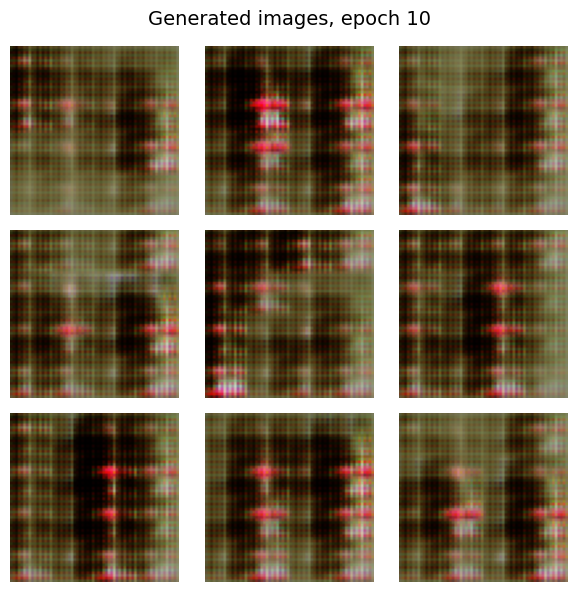

Epoch 11/25: 100%|██████████| 196/196 [00:42<00:00,  4.65it/s]


Epoch 11/25 - D Loss: 1.0043 - G Loss: 1.6782 - D(x): 0.664 - D(G(z)): 0.330


Epoch 12/25: 100%|██████████| 196/196 [00:42<00:00,  4.63it/s]


Epoch 12/25 - D Loss: 1.0357 - G Loss: 1.4932 - D(x): 0.649 - D(G(z)): 0.351


Epoch 13/25: 100%|██████████| 196/196 [00:42<00:00,  4.59it/s]


Epoch 13/25 - D Loss: 0.9930 - G Loss: 1.7585 - D(x): 0.673 - D(G(z)): 0.323


Epoch 14/25: 100%|██████████| 196/196 [00:41<00:00,  4.67it/s]


Epoch 14/25 - D Loss: 1.0231 - G Loss: 1.7311 - D(x): 0.651 - D(G(z)): 0.331


Epoch 15/25: 100%|██████████| 196/196 [00:42<00:00,  4.65it/s]


Epoch 15/25 - D Loss: 0.9943 - G Loss: 1.5771 - D(x): 0.673 - D(G(z)): 0.344


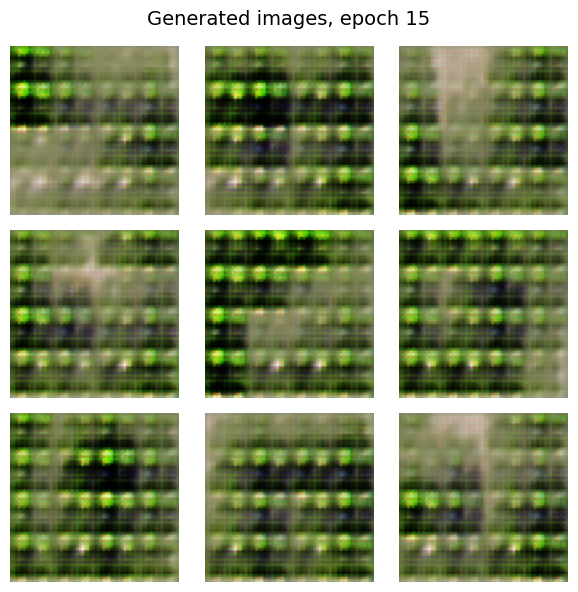

Epoch 16/25: 100%|██████████| 196/196 [00:43<00:00,  4.52it/s]


Epoch 16/25 - D Loss: 0.9467 - G Loss: 1.9224 - D(x): 0.695 - D(G(z)): 0.314


Epoch 17/25: 100%|██████████| 196/196 [00:43<00:00,  4.49it/s]


Epoch 17/25 - D Loss: 1.0236 - G Loss: 1.9171 - D(x): 0.668 - D(G(z)): 0.325


Epoch 18/25: 100%|██████████| 196/196 [00:43<00:00,  4.53it/s]


Epoch 18/25 - D Loss: 0.9836 - G Loss: 1.8656 - D(x): 0.670 - D(G(z)): 0.325


Epoch 19/25: 100%|██████████| 196/196 [00:43<00:00,  4.49it/s]


Epoch 19/25 - D Loss: 0.9097 - G Loss: 1.9856 - D(x): 0.696 - D(G(z)): 0.312


Epoch 20/25: 100%|██████████| 196/196 [00:48<00:00,  4.03it/s]


Epoch 20/25 - D Loss: 1.0117 - G Loss: 1.9629 - D(x): 0.666 - D(G(z)): 0.325


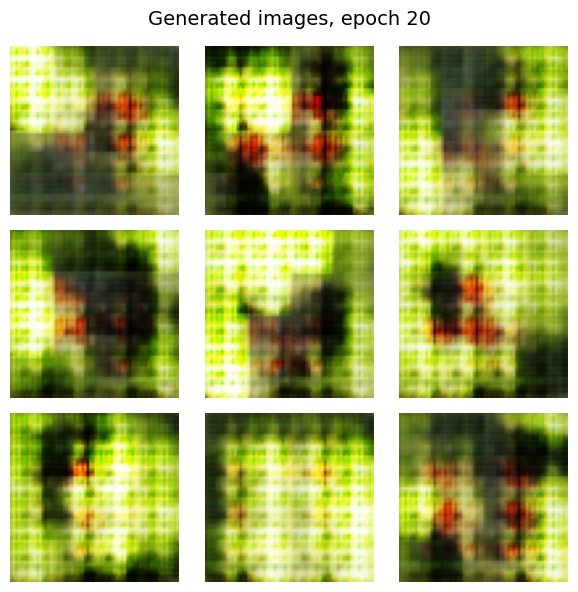

Epoch 21/25: 100%|██████████| 196/196 [00:55<00:00,  3.51it/s]


Epoch 21/25 - D Loss: 0.9167 - G Loss: 2.2021 - D(x): 0.694 - D(G(z)): 0.299


Epoch 22/25: 100%|██████████| 196/196 [00:45<00:00,  4.35it/s]


Epoch 22/25 - D Loss: 0.9102 - G Loss: 2.0831 - D(x): 0.696 - D(G(z)): 0.305


Epoch 23/25: 100%|██████████| 196/196 [00:43<00:00,  4.56it/s]


Epoch 23/25 - D Loss: 0.9342 - G Loss: 2.3127 - D(x): 0.687 - D(G(z)): 0.296


Epoch 24/25: 100%|██████████| 196/196 [00:43<00:00,  4.47it/s]


Epoch 24/25 - D Loss: 0.9062 - G Loss: 2.2609 - D(x): 0.708 - D(G(z)): 0.297


Epoch 25/25: 100%|██████████| 196/196 [00:43<00:00,  4.50it/s]


Epoch 25/25 - D Loss: 1.0131 - G Loss: 1.7496 - D(x): 0.662 - D(G(z)): 0.335


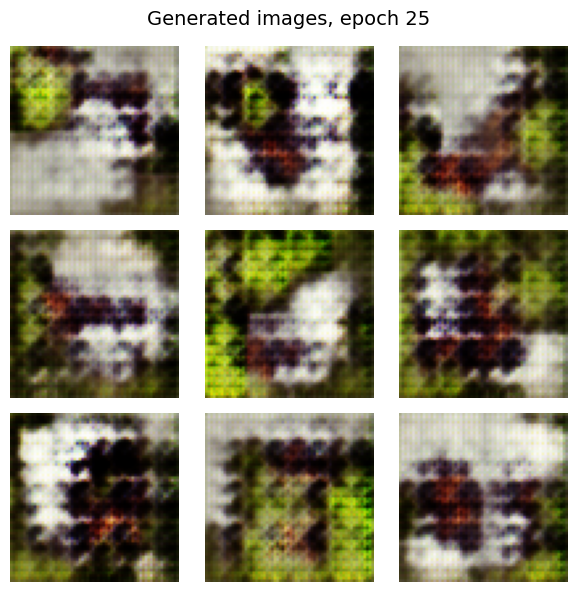

In [10]:
###############################################################
# Train the GAN model (Version 1)
###############################################################

torch.manual_seed(99)

# Build and train the GAN model (scaled to [-1, 1])
latent_dim = 256
n_epochs = 25

# Initialise the Generator and the Discriminator
generator = Generator(latent_dim=latent_dim, out_channels=3, filters=128).to(device)
discriminator = Discriminator(in_channels=3, filters=128).to(device)

# Train the GAN
d_loss_history, g_loss_history, d_real_history, d_fake_history = train_gan(
    generator, discriminator, train_loader, latent_dim=latent_dim, n_epochs=n_epochs)

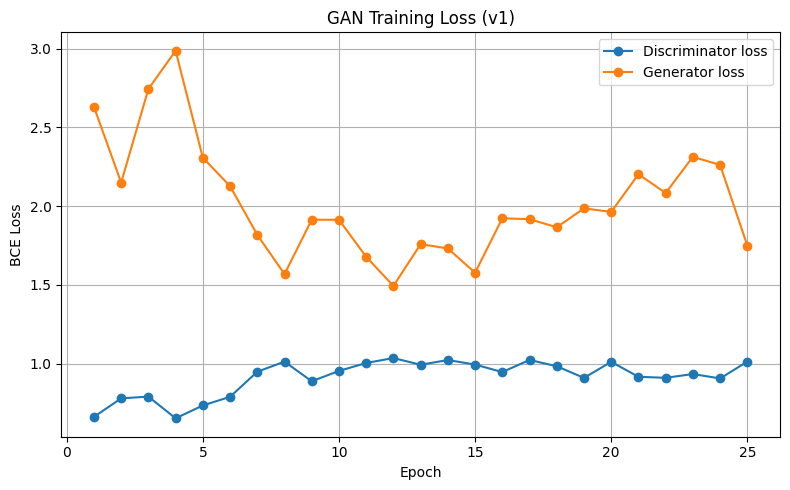

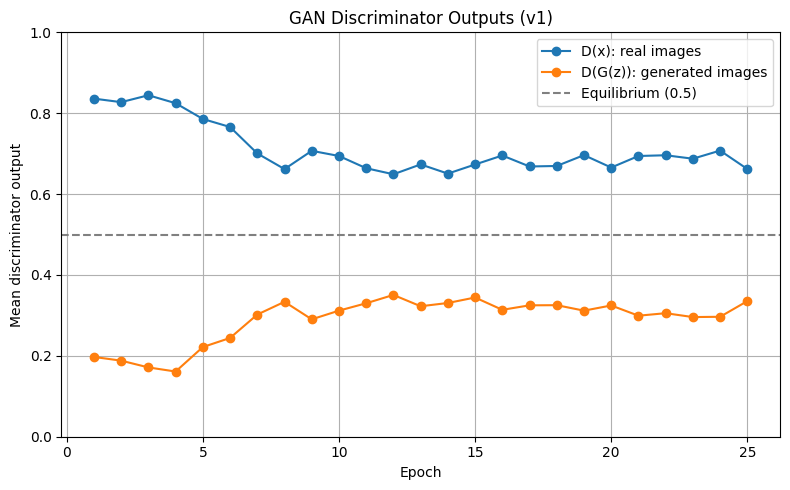

In [19]:
###############################################################
# Plot Losses Training Version 2
###############################################################

# Fix names to add version number
d_loss_v1, g_loss_v1, d_real_v1, d_fake_v1 = d_loss_history, g_loss_history, d_real_history, d_fake_history

plot_training_history(d_loss_v1, g_loss_v1, d_real_v1, d_fake_v1, version='v1')

In [12]:
## Train V1 (notebook architecture, 25 epochs)
# - Training is stable
# - In the losses, the discriminator is still dominating but that's expected
# - In the probabilities, values are stable, we are not at the perfect 0.5% yet
# - The images don't show butterflies yet. There are good colours but no shape. Noticeable checkerboard
# - The images look quite similar (same colours) while we know the raw ones have different colours and shapes (mode dropping?)

## Improvements:
# - Add BatchNorm Layer: rescale the values in the batch to mean 0 and sd 1 to keep the numbers flowing through the network in a good range
# - kernel_size = 4 instead of 3 in the strided layers. Higher resolution. It’s also what DCGAN uses.
# - We don't add epochs for now, the training appears stable from the plots

## Training Version 2

In [20]:
###############################################################
# Decoder for the Generator V2 (kernel = 4x4, add layer = BatchNorm)
###############################################################
class ConvDecoderDCGAN(nn.Module):
    """
    Same as the notebook's ConvDecoder, but with kernel_size=4 (no checkerboard artefacts) and BatchNorm (as in DCGAN)
    """
    def __init__(self, latent_dim=512, out_channels=3, filters=128, n_upsampling_layers=4, activation_out='sigmoid'):
        super().__init__()
        self.filters = filters
        self.fc = nn.Linear(latent_dim, filters * 4 * 4)
        self.bn_fc = nn.BatchNorm1d(filters * 4 * 4) #NB. BatchNorm after the linear layer
        layers = []
        for _ in range(n_upsampling_layers):
            layers.append(nn.ConvTranspose2d(filters, filters, kernel_size=4, stride=2, padding=1))   #NB. kernel 3 -> 4
            layers.append(nn.BatchNorm2d(filters)) #NB. BatchNorm after each upsampling layer
            layers.append(nn.ReLU(inplace=True))
        self.deconv_net = nn.Sequential(*layers)
        self.conv_out = nn.Conv2d(filters, out_channels, kernel_size=3, stride=1, padding=1)
        self.activation_out = activation_out

    def forward(self, z):
        h = F.relu(self.bn_fc(self.fc(z)))
        h = h.view(-1, self.filters, 4, 4)
        h = self.deconv_net(h)
        out = self.conv_out(h)
        if self.activation_out == 'sigmoid':
            return torch.sigmoid(out)
        elif self.activation_out == 'tanh':
            return torch.tanh(out)
        return out

###############################################################
# GAN Generator V2 (kernel = 4x4, add layer = BatchNorm)
###############################################################
class Generator(nn.Module):
    """
    Generator deconvolutional network with Tanh output activation in [-1, 1]
    """
    def __init__(self, latent_dim=256, out_channels=3, filters=128):
        super().__init__()
        self.decoder = ConvDecoderDCGAN(latent_dim=latent_dim, out_channels=out_channels, filters=filters, activation_out='tanh')   #NB. ConvDecoderDCGAN instead of ConvDecoder

    def forward(self, z):
        return self.decoder(z)

In [21]:
###############################################################
# GAN Generator, Version 2 (DCGAN-style)
###############################################################
class GeneratorV2(nn.Module):
    """
    Generator with kernel size 4 and BatchNorm, Tanh output activation in [-1, 1]
    """
    def __init__(self, latent_dim=256, out_channels=3, filters=128):
        super().__init__()
        self.decoder = ConvDecoderDCGAN(latent_dim=latent_dim, out_channels=out_channels, filters=filters, activation_out='tanh')

    def forward(self, z):
        return self.decoder(z)

###############################################################
# GAN Discriminator V2 (kernel = 4x4, add layer = BatchNorm)
###############################################################
class DiscriminatorV2(nn.Module):
    """
    Discriminator with kernel size 4 and BatchNorm (not after the first layer)
    """
    def __init__(self, in_channels=3, filters=128):
        super().__init__()
        self.net = nn.Sequential(
            nn.Conv2d(in_channels, filters, kernel_size=4, stride=2, padding=1),
            nn.LeakyReLU(0.2, inplace=True),
            nn.Conv2d(filters, filters, kernel_size=4, stride=2, padding=1),
            nn.BatchNorm2d(filters),
            nn.LeakyReLU(0.2, inplace=True),
            nn.Conv2d(filters, filters, kernel_size=4, stride=2, padding=1),
            nn.BatchNorm2d(filters),
            nn.LeakyReLU(0.2, inplace=True),
            nn.Conv2d(filters, filters, kernel_size=4, stride=2, padding=1),
            nn.BatchNorm2d(filters),
            nn.LeakyReLU(0.2, inplace=True),
            nn.Flatten(),
            nn.Linear(filters * 4 * 4, 1),
            nn.Sigmoid()
        )

    def forward(self, x):
        return self.net(x)

Epoch 1/25: 100%|██████████| 196/196 [00:46<00:00,  4.26it/s]


Epoch 1/25 - D Loss: 0.7723 - G Loss: 3.2231 - D(x): 0.696 - D(G(z)): 0.272


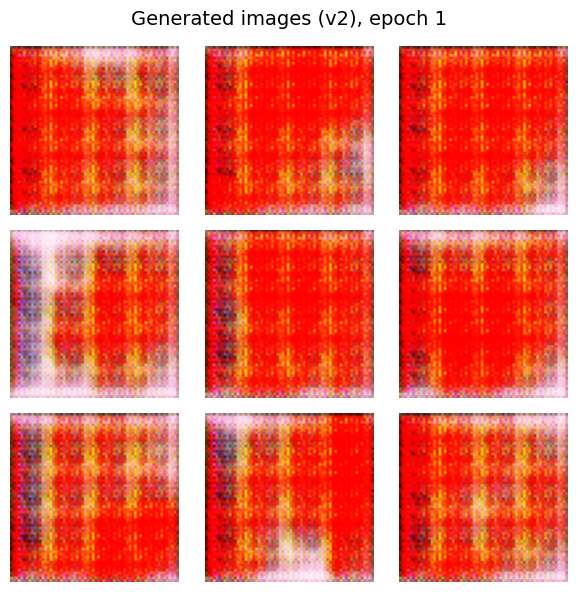

Epoch 2/25: 100%|██████████| 196/196 [00:46<00:00,  4.17it/s]


Epoch 2/25 - D Loss: 0.5230 - G Loss: 4.0733 - D(x): 0.802 - D(G(z)): 0.184


Epoch 3/25: 100%|██████████| 196/196 [00:47<00:00,  4.13it/s]


Epoch 3/25 - D Loss: 0.7324 - G Loss: 3.1059 - D(x): 0.738 - D(G(z)): 0.257


Epoch 4/25: 100%|██████████| 196/196 [00:46<00:00,  4.24it/s]


Epoch 4/25 - D Loss: 0.7909 - G Loss: 2.6465 - D(x): 0.713 - D(G(z)): 0.282


Epoch 5/25: 100%|██████████| 196/196 [00:45<00:00,  4.26it/s]


Epoch 5/25 - D Loss: 0.6906 - G Loss: 3.1376 - D(x): 0.741 - D(G(z)): 0.250


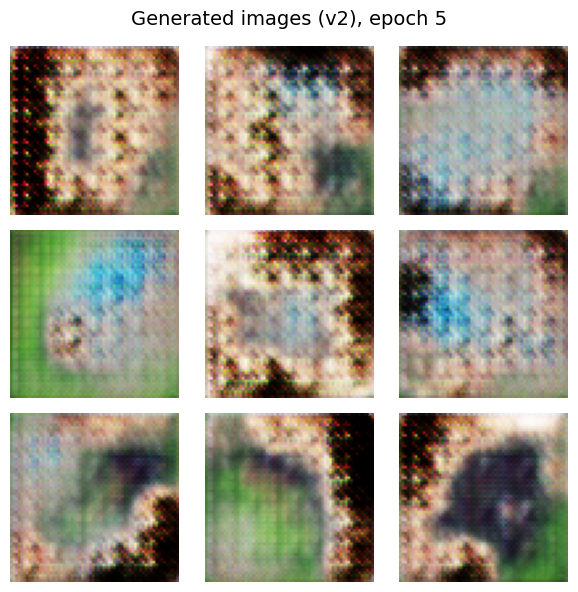

Epoch 6/25: 100%|██████████| 196/196 [00:46<00:00,  4.26it/s]


Epoch 6/25 - D Loss: 0.7163 - G Loss: 2.8978 - D(x): 0.734 - D(G(z)): 0.259


Epoch 7/25: 100%|██████████| 196/196 [00:46<00:00,  4.22it/s]


Epoch 7/25 - D Loss: 0.7768 - G Loss: 2.5292 - D(x): 0.713 - D(G(z)): 0.281


Epoch 8/25: 100%|██████████| 196/196 [00:46<00:00,  4.23it/s]


Epoch 8/25 - D Loss: 0.7136 - G Loss: 2.8934 - D(x): 0.741 - D(G(z)): 0.257


Epoch 9/25: 100%|██████████| 196/196 [00:46<00:00,  4.25it/s]


Epoch 9/25 - D Loss: 0.7356 - G Loss: 2.8110 - D(x): 0.731 - D(G(z)): 0.263


Epoch 10/25: 100%|██████████| 196/196 [00:46<00:00,  4.21it/s]


Epoch 10/25 - D Loss: 0.6773 - G Loss: 2.9406 - D(x): 0.749 - D(G(z)): 0.245


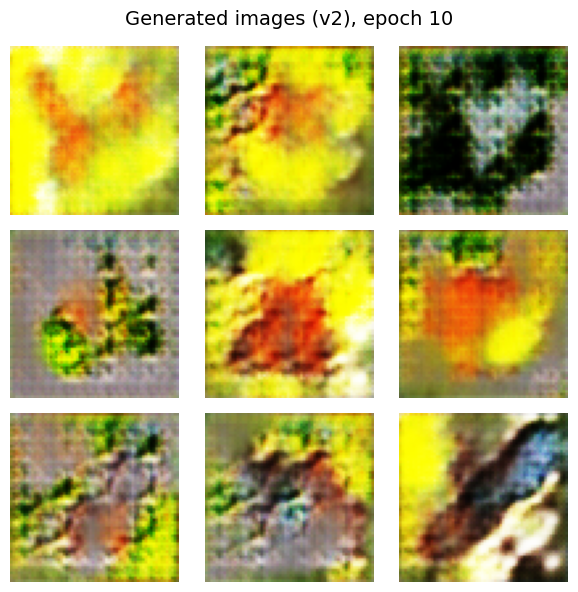

Epoch 11/25: 100%|██████████| 196/196 [00:47<00:00,  4.15it/s]


Epoch 11/25 - D Loss: 0.6068 - G Loss: 3.1945 - D(x): 0.772 - D(G(z)): 0.225


Epoch 12/25: 100%|██████████| 196/196 [00:46<00:00,  4.19it/s]


Epoch 12/25 - D Loss: 0.6115 - G Loss: 3.2234 - D(x): 0.776 - D(G(z)): 0.220


Epoch 13/25: 100%|██████████| 196/196 [00:47<00:00,  4.11it/s]


Epoch 13/25 - D Loss: 0.6648 - G Loss: 2.8503 - D(x): 0.755 - D(G(z)): 0.240


Epoch 14/25: 100%|██████████| 196/196 [00:47<00:00,  4.16it/s]


Epoch 14/25 - D Loss: 0.6148 - G Loss: 2.9521 - D(x): 0.772 - D(G(z)): 0.225


Epoch 15/25: 100%|██████████| 196/196 [00:46<00:00,  4.18it/s]


Epoch 15/25 - D Loss: 0.6373 - G Loss: 2.8105 - D(x): 0.766 - D(G(z)): 0.232


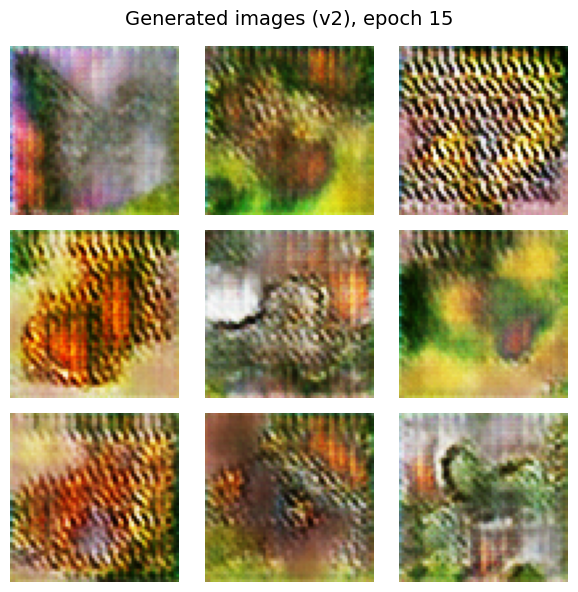

Epoch 16/25: 100%|██████████| 196/196 [00:47<00:00,  4.15it/s]


Epoch 16/25 - D Loss: 0.5792 - G Loss: 2.9373 - D(x): 0.783 - D(G(z)): 0.214


Epoch 17/25: 100%|██████████| 196/196 [00:48<00:00,  4.06it/s]


Epoch 17/25 - D Loss: 0.6082 - G Loss: 2.7641 - D(x): 0.772 - D(G(z)): 0.225


Epoch 18/25: 100%|██████████| 196/196 [00:48<00:00,  4.06it/s]


Epoch 18/25 - D Loss: 0.5827 - G Loss: 2.9046 - D(x): 0.785 - D(G(z)): 0.211


Epoch 19/25: 100%|██████████| 196/196 [00:47<00:00,  4.12it/s]


Epoch 19/25 - D Loss: 0.5622 - G Loss: 2.7812 - D(x): 0.787 - D(G(z)): 0.211


Epoch 20/25: 100%|██████████| 196/196 [00:47<00:00,  4.11it/s]


Epoch 20/25 - D Loss: 0.5690 - G Loss: 2.9626 - D(x): 0.791 - D(G(z)): 0.205


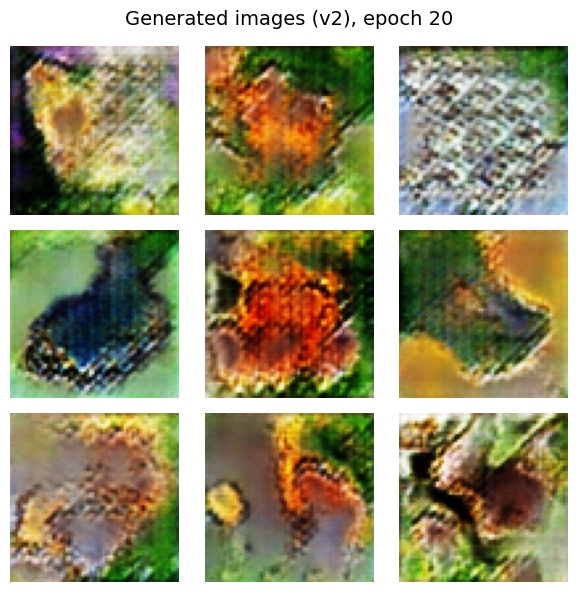

Epoch 21/25: 100%|██████████| 196/196 [00:48<00:00,  4.02it/s]


Epoch 21/25 - D Loss: 0.5635 - G Loss: 2.8664 - D(x): 0.791 - D(G(z)): 0.207


Epoch 22/25: 100%|██████████| 196/196 [00:50<00:00,  3.90it/s]


Epoch 22/25 - D Loss: 0.5217 - G Loss: 2.8770 - D(x): 0.801 - D(G(z)): 0.197


Epoch 23/25: 100%|██████████| 196/196 [00:48<00:00,  4.00it/s]


Epoch 23/25 - D Loss: 0.5161 - G Loss: 2.9629 - D(x): 0.808 - D(G(z)): 0.190


Epoch 24/25: 100%|██████████| 196/196 [00:48<00:00,  4.07it/s]


Epoch 24/25 - D Loss: 0.4678 - G Loss: 3.0698 - D(x): 0.822 - D(G(z)): 0.176


Epoch 25/25: 100%|██████████| 196/196 [00:48<00:00,  4.05it/s]


Epoch 25/25 - D Loss: 0.4896 - G Loss: 3.1082 - D(x): 0.817 - D(G(z)): 0.178


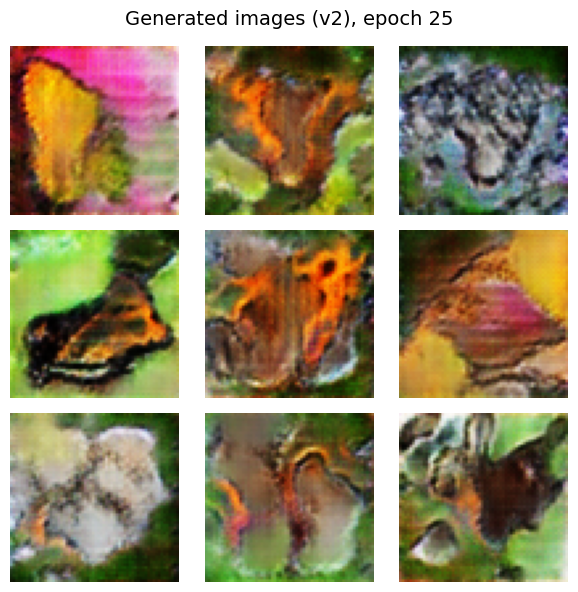

In [25]:
###############################################################
# Training V2 (kernel = 4x4, add layer = BatchNorm)
###############################################################

torch.manual_seed(99)

# Build and train the GAN model (scaled to [-1, 1])
latent_dim = 256
n_epochs = 25

# Initialise the Generator and the Discriminator
generator_v2 = GeneratorV2(latent_dim=latent_dim, out_channels=3, filters=num_filters).to(device)
discriminator_v2 = DiscriminatorV2(in_channels=3, filters=num_filters).to(device)

# Train GAN
d_loss_v2, g_loss_v2, d_real_v2, d_fake_v2 = train_gan(
    generator_v2, discriminator_v2, train_loader, latent_dim=latent_dim, n_epochs=n_epochs, version='v2')

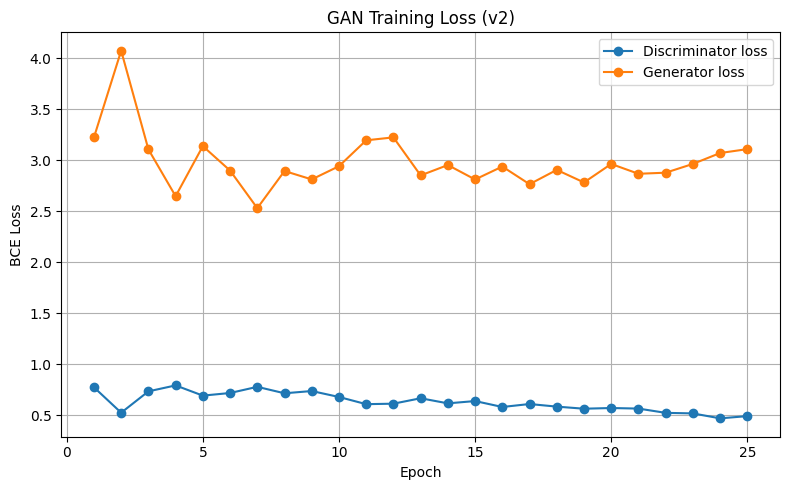

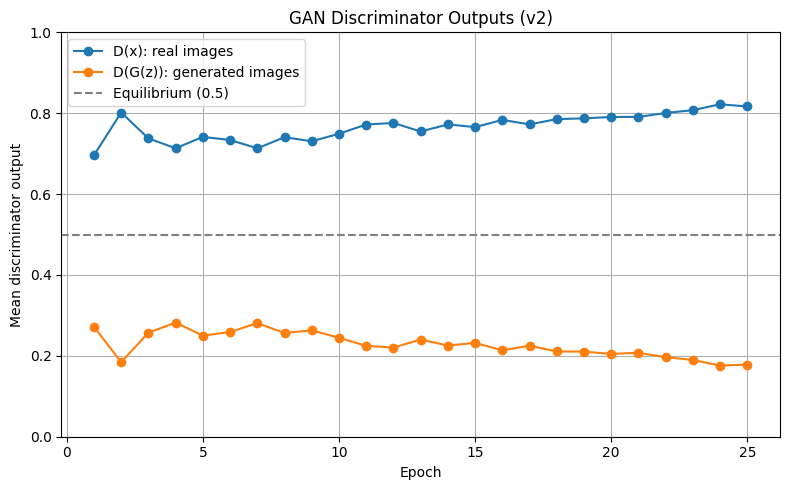

In [26]:
###############################################################
# Plot Losses Training Version 2
###############################################################

plot_training_history(d_loss_v2, g_loss_v2, d_real_v2, d_fake_v2, version='v2')

In [ ]:
## Train V2 (deeper architecture, 25 epochs)
# - The images started showing the wings outline. No longer noticeable checkerboard
# - The images don't look similar anymore
# - The losses look a bit worse: BatchNorm made both networks stronger. D is now better at spotting fakes, which pushes G’s loss up.
#   But a stronger D also gives G more informative feedback, so G improved in absolute terms, even though it’s relatively “losing” to D.
# - The discriminator loss is going down, and looks relatively stable.
# - NB. The GAN Loss functions measure the balance of the minimax game between Generator and Discriminator, not the image quality.
# - NB2. Wnlike the CAE/VAE, where more training simply lowers the loss, a GAN’s balance can drift over time
# - NB3. V2 took about 47s, while V1 took about 41s (this improvement costs roughly 15% more training time) (bigger kernels plus BatchNorm)

## Improvements:
# - Check if now adding more epochs improves results (if not we go back to 25)

## Training Version 3

Epoch 1/50: 100%|██████████| 196/196 [00:49<00:00,  3.98it/s]


Epoch 1/50 - D Loss: 0.8058 - G Loss: 2.9953 - D(x): 0.698 - D(G(z)): 0.287


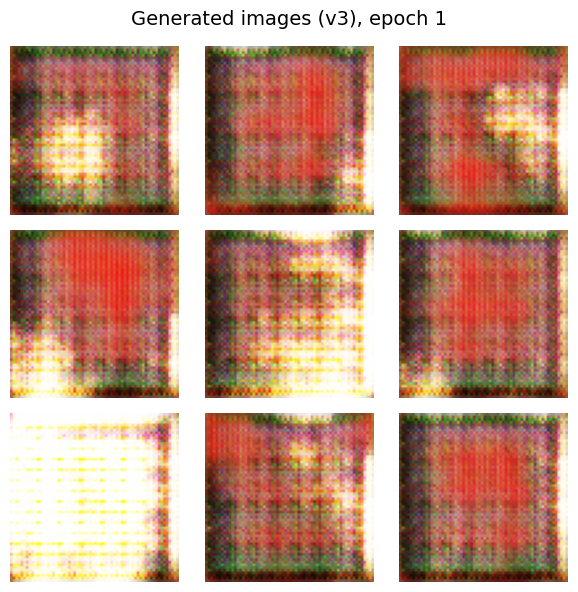

Epoch 2/50: 100%|██████████| 196/196 [00:49<00:00,  3.97it/s]


Epoch 2/50 - D Loss: 0.7700 - G Loss: 2.9501 - D(x): 0.717 - D(G(z)): 0.266


Epoch 3/50: 100%|██████████| 196/196 [00:48<00:00,  4.04it/s]


Epoch 3/50 - D Loss: 0.6255 - G Loss: 3.4189 - D(x): 0.765 - D(G(z)): 0.226


Epoch 4/50: 100%|██████████| 196/196 [00:48<00:00,  4.02it/s]


Epoch 4/50 - D Loss: 0.8446 - G Loss: 2.6094 - D(x): 0.700 - D(G(z)): 0.300


Epoch 5/50: 100%|██████████| 196/196 [00:51<00:00,  3.81it/s]


Epoch 5/50 - D Loss: 0.7932 - G Loss: 2.8525 - D(x): 0.715 - D(G(z)): 0.279


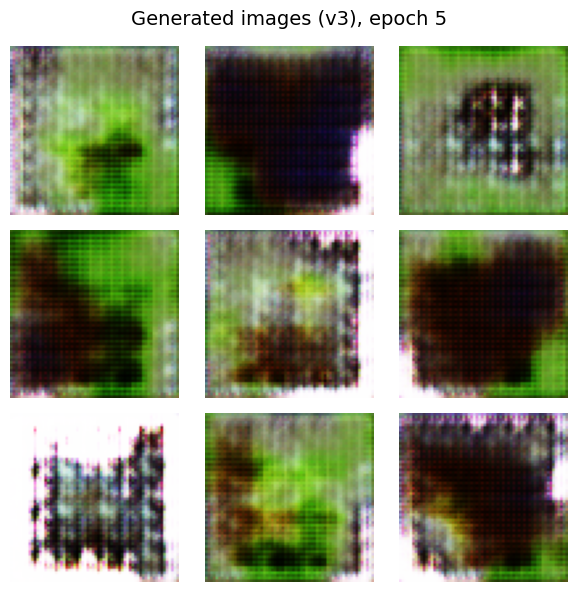

Epoch 6/50: 100%|██████████| 196/196 [00:54<00:00,  3.62it/s]


Epoch 6/50 - D Loss: 0.7011 - G Loss: 3.2819 - D(x): 0.744 - D(G(z)): 0.251


Epoch 7/50: 100%|██████████| 196/196 [00:51<00:00,  3.83it/s]


Epoch 7/50 - D Loss: 0.7335 - G Loss: 2.8194 - D(x): 0.731 - D(G(z)): 0.266


Epoch 8/50: 100%|██████████| 196/196 [00:53<00:00,  3.70it/s]


Epoch 8/50 - D Loss: 0.7469 - G Loss: 2.5997 - D(x): 0.727 - D(G(z)): 0.270


Epoch 9/50: 100%|██████████| 196/196 [00:53<00:00,  3.63it/s]


Epoch 9/50 - D Loss: 0.7463 - G Loss: 2.5101 - D(x): 0.724 - D(G(z)): 0.272


Epoch 10/50: 100%|██████████| 196/196 [00:55<00:00,  3.55it/s]


Epoch 10/50 - D Loss: 0.7369 - G Loss: 2.5172 - D(x): 0.727 - D(G(z)): 0.270


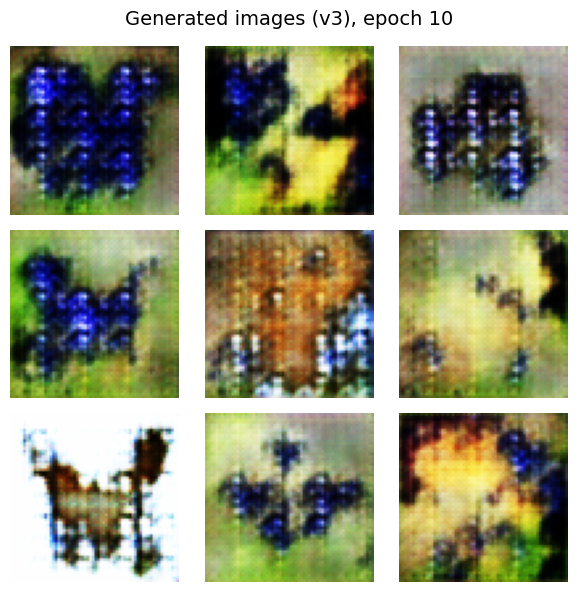

Epoch 11/50: 100%|██████████| 196/196 [00:50<00:00,  3.91it/s]


Epoch 11/50 - D Loss: 0.7062 - G Loss: 2.6481 - D(x): 0.739 - D(G(z)): 0.259


Epoch 12/50: 100%|██████████| 196/196 [00:50<00:00,  3.86it/s]


Epoch 12/50 - D Loss: 0.6819 - G Loss: 2.8315 - D(x): 0.753 - D(G(z)): 0.246


Epoch 13/50: 100%|██████████| 196/196 [00:50<00:00,  3.91it/s]


Epoch 13/50 - D Loss: 0.6359 - G Loss: 2.9768 - D(x): 0.767 - D(G(z)): 0.230


Epoch 14/50: 100%|██████████| 196/196 [00:47<00:00,  4.10it/s]


Epoch 14/50 - D Loss: 0.5980 - G Loss: 2.8965 - D(x): 0.774 - D(G(z)): 0.224


Epoch 15/50: 100%|██████████| 196/196 [00:48<00:00,  4.02it/s]


Epoch 15/50 - D Loss: 0.6326 - G Loss: 2.9207 - D(x): 0.766 - D(G(z)): 0.231


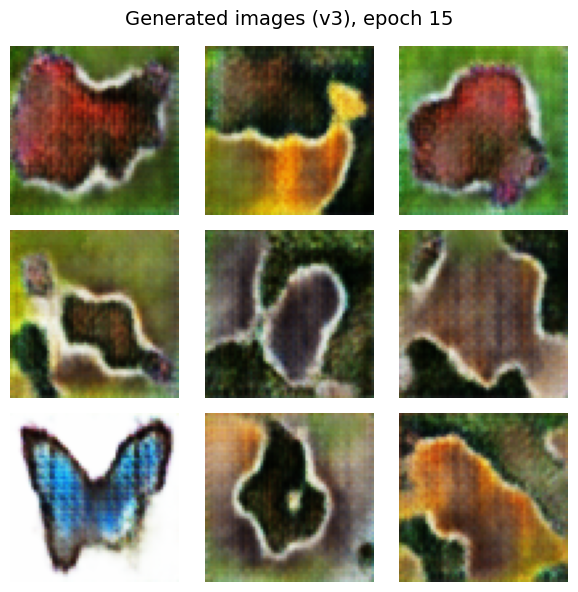

Epoch 16/50: 100%|██████████| 196/196 [00:48<00:00,  4.04it/s]


Epoch 16/50 - D Loss: 0.6563 - G Loss: 2.8467 - D(x): 0.759 - D(G(z)): 0.237


Epoch 17/50: 100%|██████████| 196/196 [00:49<00:00,  3.94it/s]


Epoch 17/50 - D Loss: 0.5746 - G Loss: 2.8876 - D(x): 0.786 - D(G(z)): 0.213


Epoch 18/50: 100%|██████████| 196/196 [00:49<00:00,  3.99it/s]


Epoch 18/50 - D Loss: 0.6094 - G Loss: 2.7117 - D(x): 0.772 - D(G(z)): 0.225


Epoch 19/50: 100%|██████████| 196/196 [00:48<00:00,  4.03it/s]


Epoch 19/50 - D Loss: 0.5720 - G Loss: 2.7576 - D(x): 0.784 - D(G(z)): 0.215


Epoch 20/50: 100%|██████████| 196/196 [00:50<00:00,  3.86it/s]


Epoch 20/50 - D Loss: 0.5287 - G Loss: 2.8635 - D(x): 0.799 - D(G(z)): 0.198


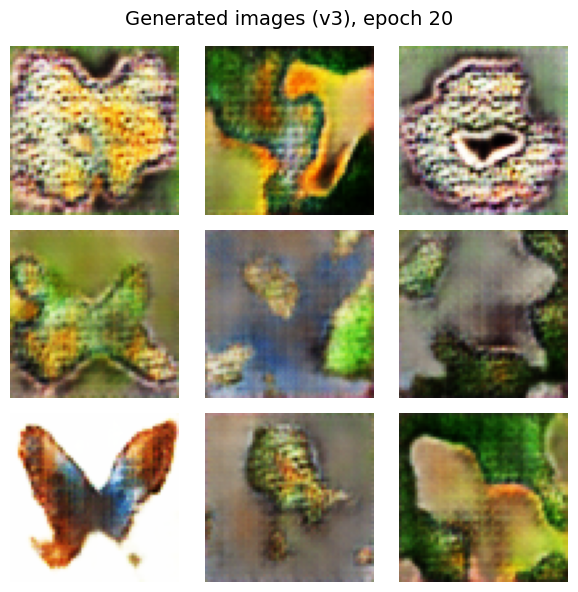

Epoch 21/50: 100%|██████████| 196/196 [00:51<00:00,  3.79it/s]


Epoch 21/50 - D Loss: 0.5005 - G Loss: 3.1246 - D(x): 0.814 - D(G(z)): 0.186


Epoch 22/50: 100%|██████████| 196/196 [00:49<00:00,  4.00it/s]


Epoch 22/50 - D Loss: 0.4934 - G Loss: 3.1229 - D(x): 0.813 - D(G(z)): 0.184


Epoch 23/50: 100%|██████████| 196/196 [00:48<00:00,  4.05it/s]


Epoch 23/50 - D Loss: 0.4385 - G Loss: 3.3089 - D(x): 0.830 - D(G(z)): 0.169


Epoch 24/50: 100%|██████████| 196/196 [00:48<00:00,  4.02it/s]


Epoch 24/50 - D Loss: 0.4499 - G Loss: 3.3646 - D(x): 0.832 - D(G(z)): 0.167


Epoch 25/50: 100%|██████████| 196/196 [00:47<00:00,  4.09it/s]


Epoch 25/50 - D Loss: 0.3957 - G Loss: 3.3874 - D(x): 0.847 - D(G(z)): 0.151


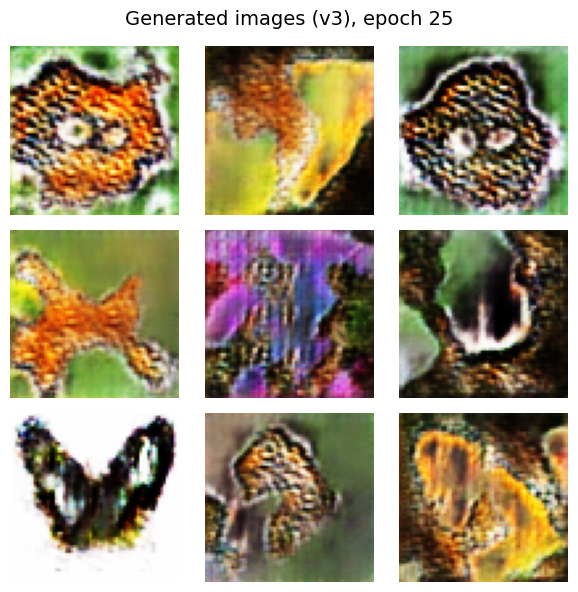

Epoch 26/50: 100%|██████████| 196/196 [00:48<00:00,  4.00it/s]


Epoch 26/50 - D Loss: 0.4361 - G Loss: 3.5066 - D(x): 0.839 - D(G(z)): 0.160


Epoch 27/50: 100%|██████████| 196/196 [00:49<00:00,  3.96it/s]


Epoch 27/50 - D Loss: 0.3968 - G Loss: 3.3956 - D(x): 0.847 - D(G(z)): 0.151


Epoch 28/50: 100%|██████████| 196/196 [00:50<00:00,  3.86it/s]


Epoch 28/50 - D Loss: 0.4422 - G Loss: 3.4188 - D(x): 0.838 - D(G(z)): 0.161


Epoch 29/50: 100%|██████████| 196/196 [00:49<00:00,  3.92it/s]


Epoch 29/50 - D Loss: 0.4048 - G Loss: 3.4083 - D(x): 0.846 - D(G(z)): 0.153


Epoch 30/50: 100%|██████████| 196/196 [00:48<00:00,  4.01it/s]


Epoch 30/50 - D Loss: 0.3670 - G Loss: 3.3968 - D(x): 0.856 - D(G(z)): 0.143


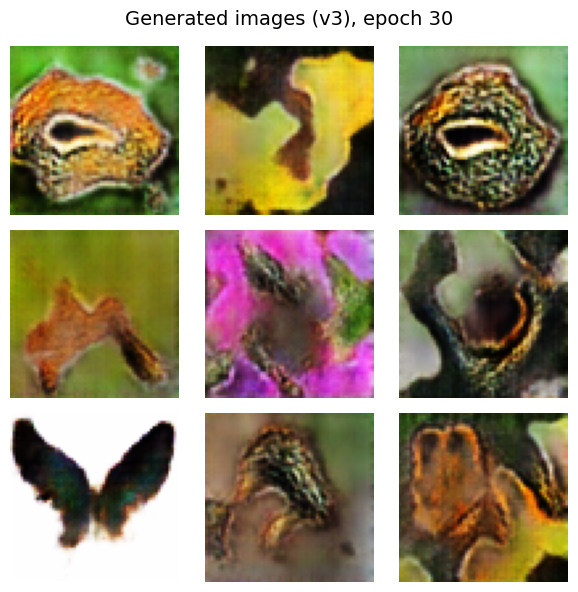

Epoch 31/50: 100%|██████████| 196/196 [00:49<00:00,  3.99it/s]


Epoch 31/50 - D Loss: 0.3487 - G Loss: 3.5559 - D(x): 0.864 - D(G(z)): 0.134


Epoch 32/50: 100%|██████████| 196/196 [00:49<00:00,  4.00it/s]


Epoch 32/50 - D Loss: 0.3869 - G Loss: 3.7483 - D(x): 0.855 - D(G(z)): 0.143


Epoch 33/50: 100%|██████████| 196/196 [00:49<00:00,  3.99it/s]


Epoch 33/50 - D Loss: 0.3691 - G Loss: 3.5694 - D(x): 0.860 - D(G(z)): 0.138


Epoch 34/50: 100%|██████████| 196/196 [00:48<00:00,  4.05it/s]


Epoch 34/50 - D Loss: 0.3424 - G Loss: 3.6085 - D(x): 0.867 - D(G(z)): 0.131


Epoch 35/50: 100%|██████████| 196/196 [00:49<00:00,  3.95it/s]


Epoch 35/50 - D Loss: 0.3443 - G Loss: 3.6010 - D(x): 0.866 - D(G(z)): 0.134


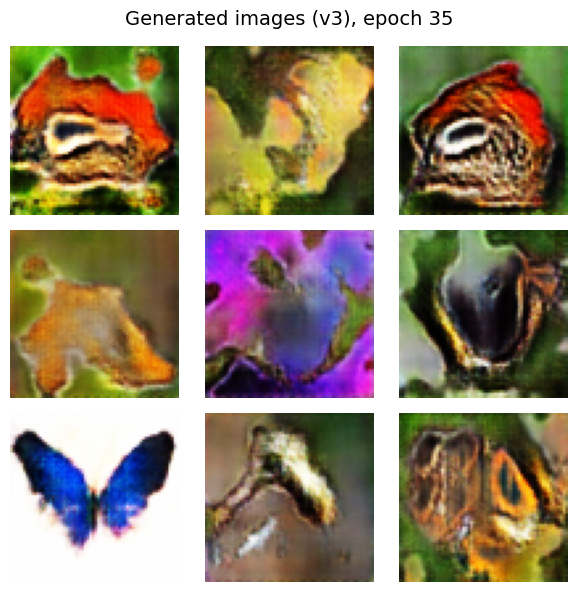

Epoch 36/50: 100%|██████████| 196/196 [00:49<00:00,  3.94it/s]


Epoch 36/50 - D Loss: 0.3832 - G Loss: 3.7178 - D(x): 0.863 - D(G(z)): 0.136


Epoch 37/50: 100%|██████████| 196/196 [00:49<00:00,  3.92it/s]


Epoch 37/50 - D Loss: 0.3462 - G Loss: 3.6113 - D(x): 0.869 - D(G(z)): 0.130


Epoch 38/50: 100%|██████████| 196/196 [00:50<00:00,  3.90it/s]


Epoch 38/50 - D Loss: 0.3303 - G Loss: 3.7085 - D(x): 0.872 - D(G(z)): 0.127


Epoch 39/50: 100%|██████████| 196/196 [00:49<00:00,  3.99it/s]


Epoch 39/50 - D Loss: 0.3751 - G Loss: 3.7233 - D(x): 0.861 - D(G(z)): 0.138


Epoch 40/50: 100%|██████████| 196/196 [00:49<00:00,  3.98it/s]


Epoch 40/50 - D Loss: 0.3879 - G Loss: 3.5912 - D(x): 0.860 - D(G(z)): 0.138


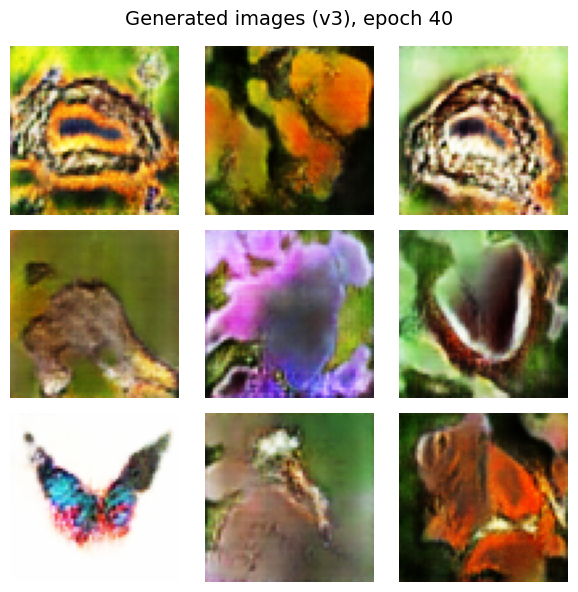

Epoch 41/50: 100%|██████████| 196/196 [00:50<00:00,  3.92it/s]


Epoch 41/50 - D Loss: 0.3290 - G Loss: 3.6185 - D(x): 0.875 - D(G(z)): 0.125


Epoch 42/50: 100%|██████████| 196/196 [00:49<00:00,  3.92it/s]


Epoch 42/50 - D Loss: 0.3271 - G Loss: 3.7413 - D(x): 0.873 - D(G(z)): 0.125


Epoch 43/50: 100%|██████████| 196/196 [00:49<00:00,  3.95it/s]


Epoch 43/50 - D Loss: 0.3451 - G Loss: 3.6750 - D(x): 0.870 - D(G(z)): 0.130


Epoch 44/50: 100%|██████████| 196/196 [00:53<00:00,  3.66it/s]


Epoch 44/50 - D Loss: 0.3022 - G Loss: 3.6021 - D(x): 0.879 - D(G(z)): 0.120


Epoch 45/50: 100%|██████████| 196/196 [00:54<00:00,  3.58it/s]


Epoch 45/50 - D Loss: 0.4216 - G Loss: 3.8526 - D(x): 0.859 - D(G(z)): 0.141


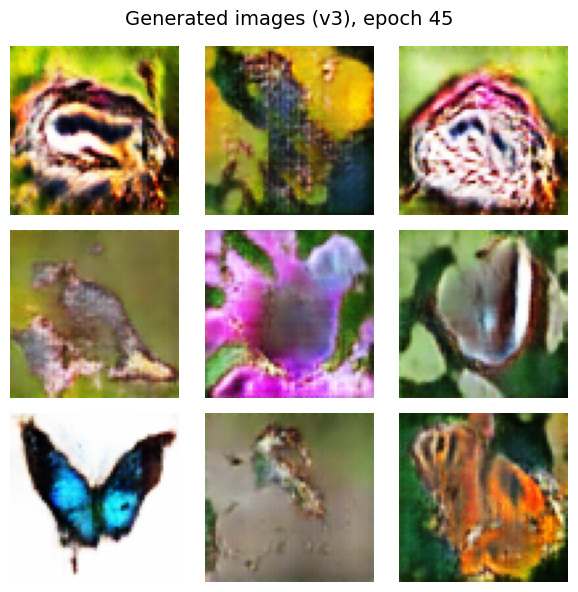

Epoch 46/50: 100%|██████████| 196/196 [00:54<00:00,  3.61it/s]


Epoch 46/50 - D Loss: 0.3024 - G Loss: 3.5425 - D(x): 0.878 - D(G(z)): 0.121


Epoch 47/50: 100%|██████████| 196/196 [00:54<00:00,  3.61it/s]


Epoch 47/50 - D Loss: 0.3376 - G Loss: 3.7488 - D(x): 0.871 - D(G(z)): 0.127


Epoch 48/50: 100%|██████████| 196/196 [00:54<00:00,  3.59it/s]


Epoch 48/50 - D Loss: 0.3223 - G Loss: 3.6997 - D(x): 0.877 - D(G(z)): 0.122


Epoch 49/50: 100%|██████████| 196/196 [00:53<00:00,  3.67it/s]


Epoch 49/50 - D Loss: 0.2703 - G Loss: 3.9151 - D(x): 0.895 - D(G(z)): 0.107


Epoch 50/50: 100%|██████████| 196/196 [00:53<00:00,  3.69it/s]


Epoch 50/50 - D Loss: 0.3581 - G Loss: 3.8413 - D(x): 0.873 - D(G(z)): 0.125


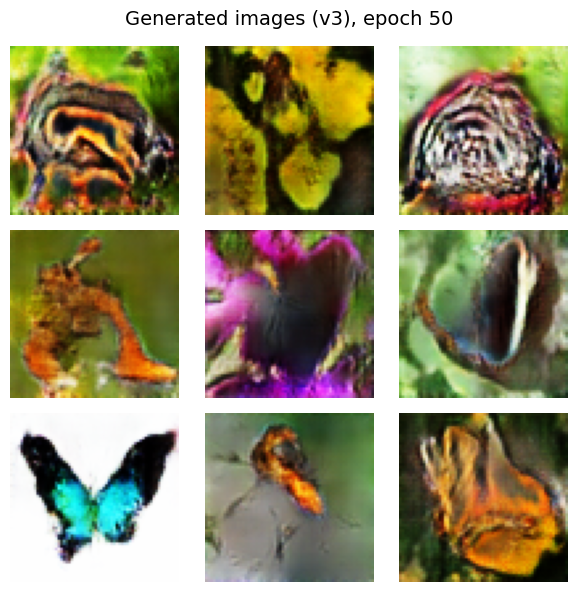

In [27]:
###############################################################
# Training V3 (architecture V2, with 50 epochs)
###############################################################
torch.manual_seed(99)   # same random starting point for every version

# Build and train the GAN model (scaled to [-1, 1])
latent_dim = 256
n_epochs = 50

# Initialise the Generator and the Discriminator
generator_v3 = GeneratorV2(latent_dim=latent_dim, out_channels=3, filters=num_filters).to(device)
discriminator_v3 = DiscriminatorV2(in_channels=3, filters=num_filters).to(device)

# Train GAN
d_loss_v3, g_loss_v3, d_real_v3, d_fake_v3 = train_gan(
    generator_v3, discriminator_v3, train_loader, latent_dim=latent_dim,
    n_epochs=n_epochs, plot_every=5, version='v3')      # 50 epochs instead of 25

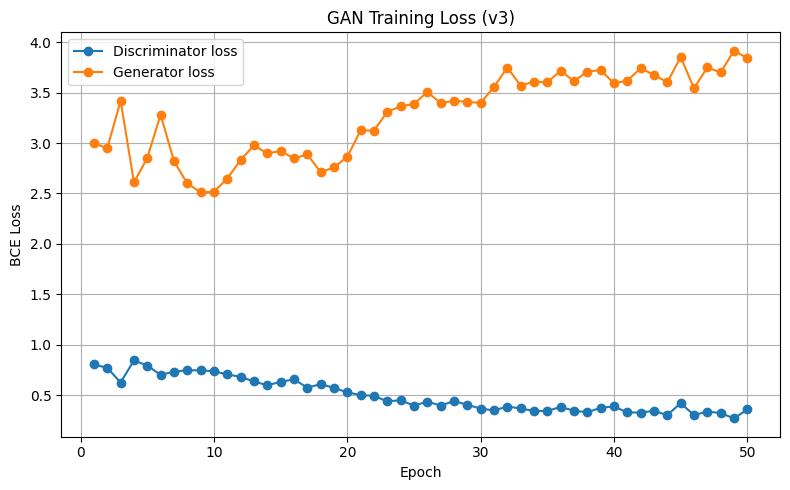

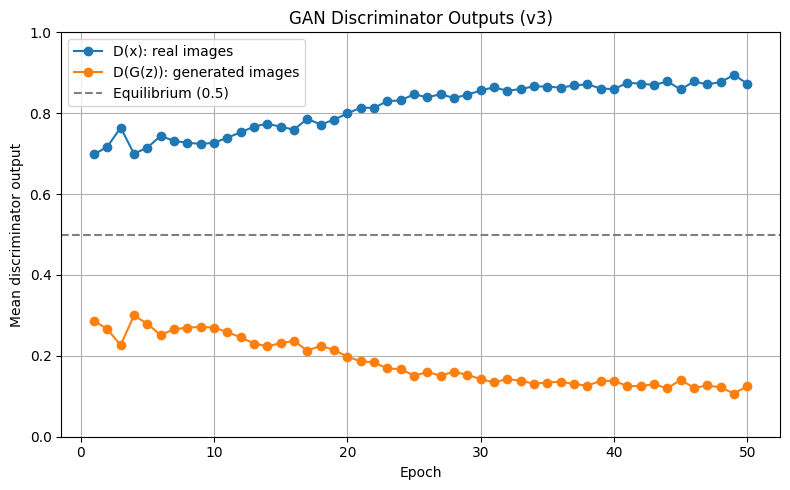

In [30]:
###############################################################
# Plot Losses Training V3
###############################################################

plot_training_history(d_loss_v3, g_loss_v3, d_real_v3, d_fake_v3, version='v3')

In [31]:
## Train V3 (architecture V2, 50 epochs)
# - More epochs improved the results: 1-10 epochs results are still pixels; 15-25 epochs shapes; 30-40 good images; 45-50 not significant.
# - Some images are still quite similar (mode dropping?)
# - Some images have a reasonable butterfly shape, some not at all (background still too confusing?)
# - The losses confirm what we saw in V2: the discriminator is still winning, and the training is stabilising too much.


## Improvements:
# - Label smoothing: instead of a hard 0,1 label, we accept also softer values (e.g., 0.3 or 0.9)

# 6. Implement latent-space interpolation (Smooth transitions between generated images)

Goal: "Explore the learned continuous latent space"
- Latent space: the space of all possible latent vectors z. Each z is a list of 256 numbers (a point in a 256-dimensional space)
- Learned: the space itself is just numbers. What’s learned is G’s mapping from points to images (the “map” from earlier).
- Exploring: means: pick points (so different z vectors), see what G makes of them.

Step 1: “Sample random latent vectors from the prior N(0, I) and feed them to the generator to create novel synthetic images”
- The latent vectors z are assumed to be normally distributed N(0,I): a multivariate normal distribution with mean 0 (a vector of 256 zeros) and covariance I (the identity matrix: 1s on the diagonal, 0s elsewhere). In plain words, each of the 256 numbers is drawn independently from a standard normal N(0, 1). That’s exactly what torch.randn(n, 256) does.
- Feed them to the generator: generator(z) turns each sampled z into an image! GANs create new synthetic images: the generator creates new images that are not in the dataset, a new image from each new point.
- Concretely: draw, say, 25 or 64 new z, generate the images, show them in a grid. That’s Step 6. It shows quality (do they look like butterflies?) and diversity (are they different from each other?).

Step 2: “Latent space interpolation”

- Pick two random points z₁ and z₂, and walk in a straight line from one to the other, generating an image at each stop. The formula describes that straight line:

$$z(\alpha) = (1-\alpha)\,z_1 + \alpha\, z_2, \qquad \alpha \in [0, 1]$$
α (“alpha”) is a number between 0 and 1 that says how far along the path you are (0 is close to the start, 1 is close to the end). It’s a weighted average: α moves the weight from z₁ to z₂. Coordinate by coordinate, each of the 256 numbers slides from its value in z₁ to its value in z₂. In practice we take e.g. 10 evenly spaced values of α (0, 0.11, 0.22, …, 1), generate the 10 images, and show them in a row. The first is G(z₁), the last is G(z₂), and the ones in between show the transition.

Why do this? “To visualise smooth transitions”

- It tests whether the latent space is well-behaved, one of the desirable properties in section 14.2 of your book: “smooth changes in z correspond to smooth changes in x”.
- Good result: the images morph gradually. The butterfly slowly changes colour, size or position, and every intermediate image still looks plausible. That means G learned a smooth, meaningful map, not a lookup table of separate images.
- Bad result: sudden jumps (several near-identical images, then an abrupt change), or garbage in the middle. That means parts of the space between z₁ and z₂ are poorly organised.

# 7. Save results and model weights